In [21]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

In [4]:
# DATA INGENSTION & EXPLORATION - TELECOM CHURN PROJECT

# Load the raw IBM Telco Churn Dataset
df_raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f'Dataset successfully loaded: {df_raw.shape[0]} rows and {df_raw.shape[1]} columns.')
print('\nFirst 3 rows of the dataset:')
print(df_raw.head(3))

Dataset successfully loaded: 7043 rows and 21 columns.

First 3 rows of the dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month              Yes   
1          No          No              No        One year               No   
2          No          No              No  Month-to-mon

In [12]:
# SQL Data Extration & Initial Cleaning
con = duckdb.connect()

# SQL to clean data types and filter the baseline dataset
query = """
SELECT
customerID,
gender,
SeniorCitizen,
Partner,
Dependents,
tenure,
PhoneService,
MultipleLines,
InternetService,
OnlineSecurity,
OnlineBackup,
DeviceProtection,
TechSupport,
StreamingTV,
StreamingMovies,
Contract,
PaperlessBilling,
PaymentMethod,
MonthlyCharges,

-- SQL FIX: Convert blank spaces to NULL and cast TotalCharges as DOUBLE
CASE
WHEN TRIM(TotalCharges) = '' THEN NULL
ELSE CAST(TotalCharges AS DOUBLE)
END AS TotalCharges,

-- SQL Target: Convert Churn Text (Yes/No) into binary integers (0/1)
CASE
WHEN Churn = 'Yes' THEN 1
ELSE 0
END AS is_churn

FROM 'WA_Fn-UseC_-Telco-Customer-Churn.csv';
"""

df = con.execute(query).df()

# Handle remaining missing values in Python (new customers with 0 tenure)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print(f'Data ingested and cleaned via SQL. Shape: {df.shape} rows')
print(f'Missing values remaining: {df['TotalCharges'].isnull().sum()}')

Data ingested and cleaned via SQL. Shape: (7043, 21) rows
Missing values remaining: 0


Churn Rate by Contract Type:
-  Month-to-month: 42.71%
-  One year: 11.27%
-  Two year: 2.83%


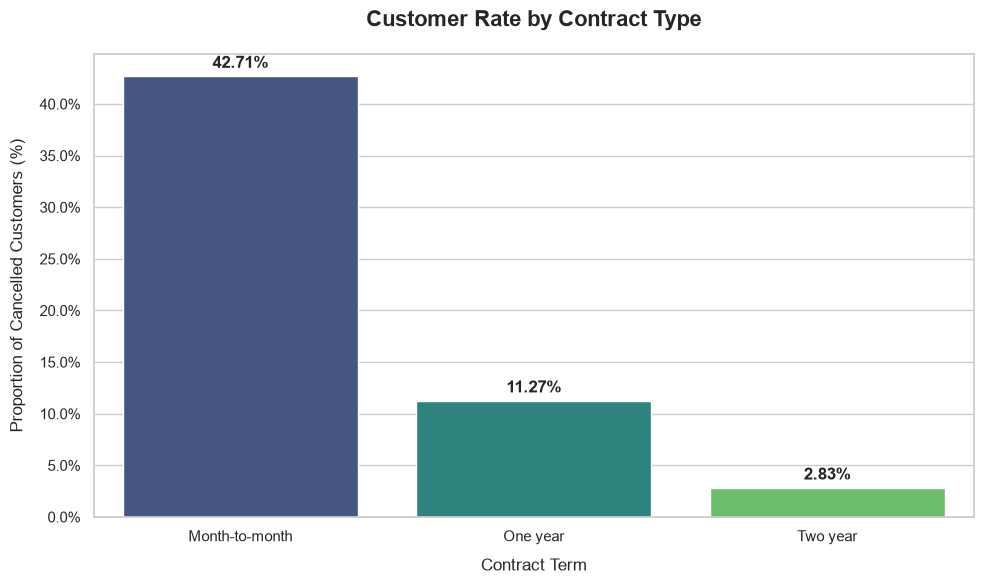

In [20]:
# Data Visualization (EDA): Churn Rate by Contract Type

# Configure the visual style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Calculate exact churn rates per contract type to print in the console
rates = df.groupby('Contract')['is_churn'].mean() * 100
print('Churn Rate by Contract Type:')
print(f'-  Month-to-month: {rates['Month-to-month']:.2f}%')
print(f'-  One year: {rates['One year']:.2f}%')
print(f'-  Two year: {rates['Two year']:.2f}%')

# Plot the churn rate comparison bar chart
ax = sns.barplot(
    x='Contract',
    y='is_churn',
    data=df,
    hue='Contract',
    legend=False,
    errorbar=None,
    palette='viridis',
    order=['Month-to-month', 'One year', 'Two year']
)

# Set descriptive chart titles and labels
plt.title('Customer Rate by Contract Type', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Contract Term', fontsize=12, labelpad=10)
plt.ylabel('Proportion of Cancelled Customers (%)', fontsize=12, labelpad=10)

# Format the Y-axis numbers as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))

# Dinamically annotate the exact percentages on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [26]:
# Machine Learning - Data Encoding & Model Training

# 1. Drop the unique identifier as it carries no predictive power
df_ml = df.drop(columns=['customerID'])

# 2. Convert all categorical text columns into numbers using One-Hot Encoding
# drop_first=True reduces redundancy (collinearity) for linear systems, good practice overall
df_encoded = pd.get_dummies(df_ml, drop_first=True)

# 3. Separate features (X) at target variable (y)
X = df_encoded.drop(columns=['is_churn'])
y = df_encoded['is_churn']

# 4. Train/Test split (80/20) with stratification to maintain churn proportions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Data encoding and partitioning complete successfully!')
print(f'Training shape: {X_train.shape} | Testing shape: {X_test.shape}')

# 5. MOdel Training via RandomForestClassifier
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train, y_train)

print('Random Forest Classifier trained successfully!')

# 6. Generate predictions and probability scores
y_pred = model_rf.predict(X_test)
y_proba = model_rf.predict_proba(X_test)[:, 1]

# 6. Evaluate the classification outcome
print('\n--- Model Performance Report ---')
print(classification_report(y_test, y_pred))
print(f'ROC-AUC Metric: {roc_auc_score(y_test, y_proba):.4f}')

Data encoding and partitioning complete successfully!
Training shape: (5634, 30) | Testing shape: (1409, 30)
Random Forest Classifier trained successfully!

--- Model Performance Report ---
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409

ROC-AUC Metric: 0.8440


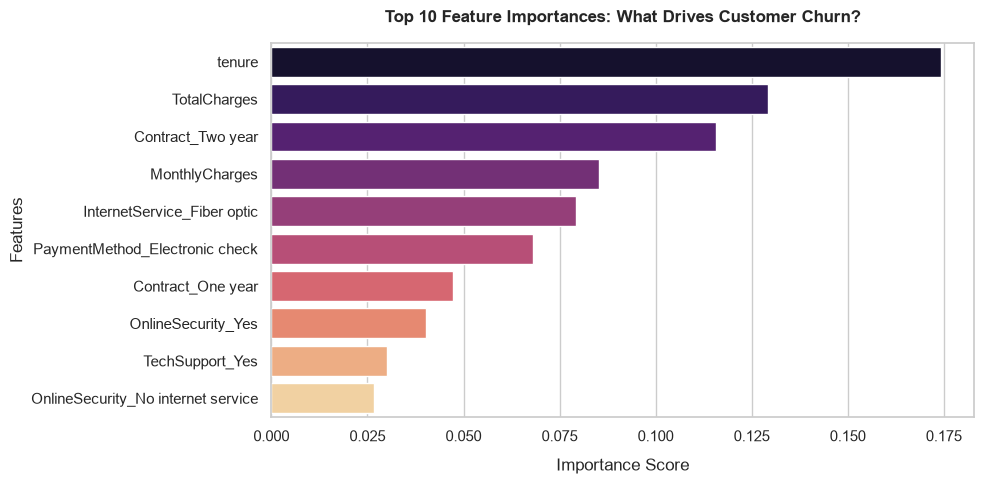

Top 10 Feature Importance Ranking:
                           Feature  Importance
                            tenure    0.174139
                      TotalCharges    0.129159
                 Contract_Two year    0.115654
                    MonthlyCharges    0.085296
       InternetService_Fiber optic    0.079308
    PaymentMethod_Electronic check    0.068186
                 Contract_One year    0.047319
                OnlineSecurity_Yes    0.040262
                   TechSupport_Yes    0.030143
OnlineSecurity_No internet service    0.026787


In [30]:
# Feature importance extraction & visualization

# Extract feature importances from the trained model
importances = model_rf.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances,
}).sort_values(by='Importance', ascending=False)

# Filter top 10 most impactful features for cleaner visualization
top_10_features = feature_imp_df.head(10)

# Configure the visualization layout
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 5))

# Plot the top 10 features as a horizontal bar chart
ax = sns.barplot(
    x='Importance',
    y='Feature',
    data=top_10_features,
    hue='Feature',
    legend=False,
    palette='magma'
)

plt.title('Top 10 Feature Importances: What Drives Customer Churn?', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Importance Score', fontsize=12, labelpad=10)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

# Print the ranking to the console
print('Top 10 Feature Importance Ranking:')
print(top_10_features.to_string(index=False))